### Make a Moddel with data Augentation
changes the data by rotating and translating it so it can reconize a larger range of numbers

In [23]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

augmentation = transforms.Compose([
    transforms.RandomRotation(15), # can be rotated up to 15 degrees
    transforms.ToTensor()
])

raw_dataset = datasets.MNIST(
    root="../data",
    train=True,
    download=True,
    transform=None
)

In [3]:
image, label = raw_dataset[0]

print("Label:", label)
print("Type:", type(image))

Label: 5
Type: <class 'PIL.Image.Image'>


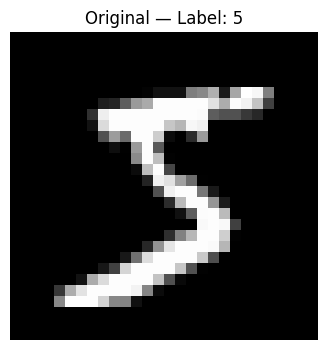

In [4]:
plt.figure(figsize=(4, 4))
plt.imshow(image, cmap="gray")
plt.title(f"Original — Label: {label}")
plt.axis("off")
plt.show()

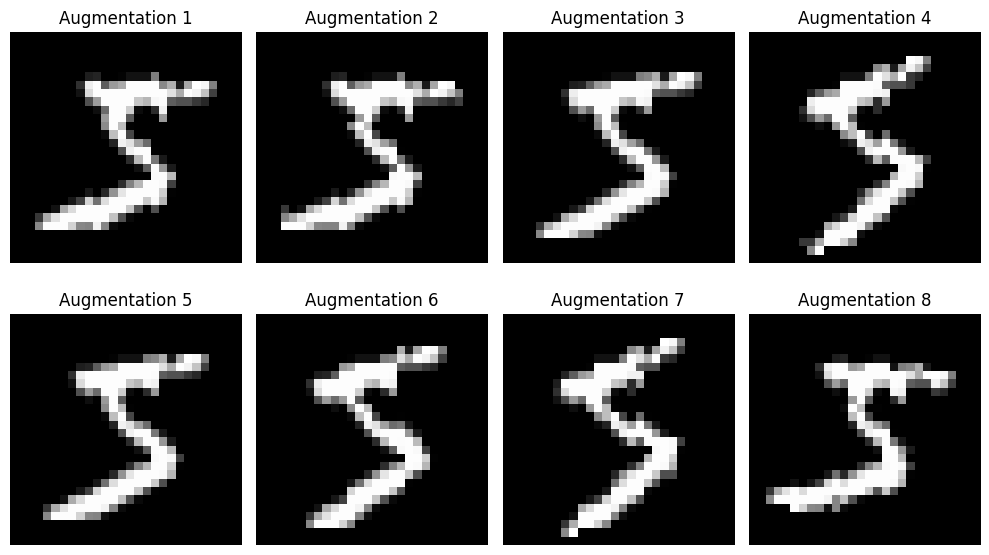

In [15]:
fig, axes = plt.subplots(2, 4, figsize=(10, 6))

for i, ax in enumerate(axes.flat):
    augmented_image = augmentation(image)

    ax.imshow(augmented_image.squeeze(), cmap="gray")
    ax.set_title(f"Augmentation {i + 1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [17]:
#rotation + translation
augmentation = transforms.Compose([
    transforms.RandomRotation(15),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.15, 0.15)
    ),
    transforms.ToTensor()
])

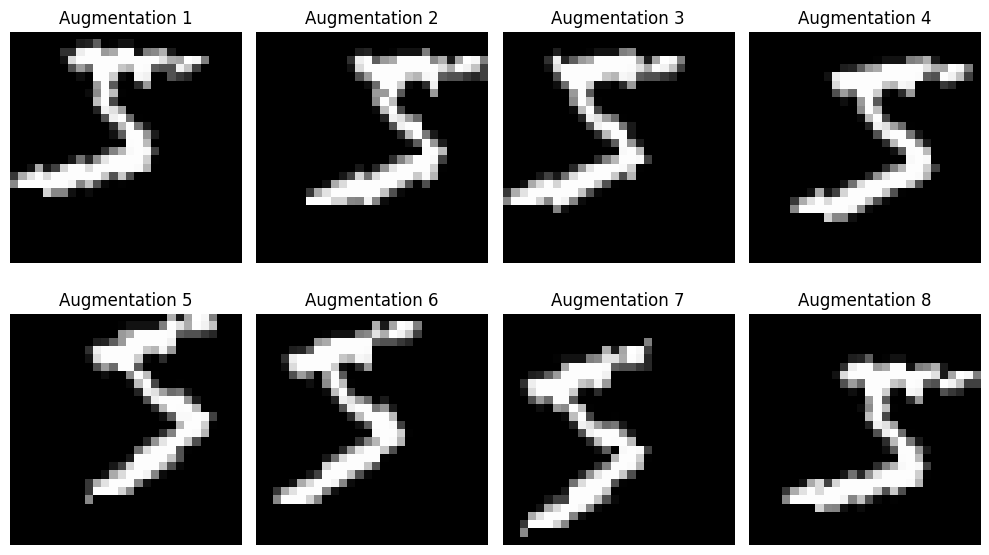

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(10, 6))

for i, ax in enumerate(axes.flat):
    augmented_image = augmentation(image)

    ax.imshow(augmented_image.squeeze(), cmap="gray")
    ax.set_title(f"Augmentation {i + 1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
#Making Models

In [24]:
train_transform = transforms.Compose([
    transforms.RandomRotation(15),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.15, 0.15)
    ),
    transforms.ToTensor()
]) # modified Transfom

test_transform = transforms.ToTensor() # normal Transform

augmented_train_dataset = datasets.MNIST(
    root="../data",
    train=True,
    download=True,
    transform=train_transform # modified Transfom
)

clean_test_dataset = datasets.MNIST(
    root="../data",
    train=False,
    download=True,
    transform=test_transform # normal Transform
)

augmented_train_loader = DataLoader(
    augmented_train_dataset,
    batch_size=64,
    shuffle=True
)

clean_test_loader = DataLoader(
    clean_test_dataset,
    batch_size=64,
    shuffle=False
)

In [26]:
cnn_aug = nn.Sequential(
    nn.Conv2d(
        in_channels=1,
        out_channels=32,
        kernel_size=3,
        padding=1
    ),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),

    nn.Conv2d(
        in_channels=32,
        out_channels=64,
        kernel_size=3,
        padding=1
    ),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),

    nn.Flatten(),
    nn.Linear(64 * 7 * 7, 10)
).to(device)

cnn_aug_loss_fn = nn.CrossEntropyLoss()

cnn_aug_optimizer = torch.optim.Adam(
    cnn_aug.parameters(),
    lr=0.001
)

In [27]:
cnn_aug_train_loss = []

for epoch in range(5):
    cnn_aug.train()
    epoch_loss = []

    for images, labels in augmented_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        cnn_aug_optimizer.zero_grad()

        output = cnn_aug(images)
        loss = cnn_aug_loss_fn(output, labels)

        epoch_loss.append(loss.item())

        loss.backward()
        cnn_aug_optimizer.step()

    average_loss = sum(epoch_loss) / len(epoch_loss)
    cnn_aug_train_loss.append(average_loss)

    print(f"Epoch {epoch + 1} -- Average Loss: {average_loss:.4f}")

Epoch 1 -- Average Loss: 0.4859
Epoch 2 -- Average Loss: 0.2044
Epoch 3 -- Average Loss: 0.1488
Epoch 4 -- Average Loss: 0.1263
Epoch 5 -- Average Loss: 0.1124


In [28]:
cnn_aug.eval()

correct_predictions = 0
total_predictions = 0

with torch.no_grad():
    for images, labels in clean_test_loader:
        images = images.to(device)
        labels = labels.to(device)

        output = cnn_aug(images)
        prediction = torch.argmax(output, dim=1)

        correct_predictions += (prediction == labels).sum().item()
        total_predictions += len(labels)

cnn_aug_test_accuracy = correct_predictions / total_predictions

print(f"Augmented CNN test accuracy: {cnn_aug_test_accuracy:.2%}")

Augmented CNN test accuracy: 98.80%
